In [ ]:
from itertools import islice
from collections import Counter
import numpy as np
import h5py
import re
import json

# Open ARCHS4 v2.1 Data
infile = "/home/ajoshi/archs4/data/archs4_gene_human_v2.1.h5"

# - Use read_direct method to improve read performance
with h5py.File(infile, 'r') as hdf5_file:
    data = hdf5_file['data']
    expression = data['expression'][:]

    meta = hdf5_file['meta']
    symbols = meta['genes']['gene_symbol'][:]
    source_name_ch1 = meta['samples']['source_name_ch1'][:]

# Decode source names using list comprehension
source_decoded = [x.decode('UTF-8') for x in source_name_ch1]

# Clean source names using regular expressions
source_cleaned = [re.sub(r'[-/\'\\ _]', '', x) for x in source_decoded]

# List of all categories (keywords)
category_list = [  # Cardiovascular
    "Heart", "Atrium", "Cardiac Muscle Fiber", "Pericardium", "Valve", "Ventricle",
    "HUVEC",  # Endothelial

    # Connective Tissue
    "Adipose", "Adipocyte",
    "Myofibroblast", "Osteoblast", "Stromal Cell", "MG63", "K562",  # Bone
    "Bone Marrow",
    "Chondrocyte",
    "HT1080", "NHDF",  # Connective

    # Digestive
    "Esophagus",
    "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", "Small Intestine",
    "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell", "HEPG2",  # Liver
    "Alpha Cell", "Beta Cell", "Pancreatic Islet", "PANC1",  # Pancreas
    "Gastric Epithelial Cell",
    "HCT116", "HT29", "RKO",  # Connective, Colon

    # Immune
    "Granulocyte", "Neutrophil",
    "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", "Tlymphocyte",
    "JURKAT", "MT4", "NALM6", "REH", "RPMI8226",  # Lymphoid
    "Alveolar", "Dendritic", "Kupffer", "Macrophage", "Macroglia",
    "THP1", "U937",  # Myeloid
    "JEG3",  # Placenta
    "Spleen",
    "Thymus", "Thymocyte",

    # Integumentary
    "Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
    "A431", "HACAT", "HNSCC",

    # Muscular
    "Skeletal Muscle", "Myoblast",
    "Airway Smooth Muscle",  # "Myofibroblast", [Repeat]
    "Respiratory Smooth Muscle", "Vascular Smooth Muscle",
    "LHCNM2",  # Muscle

    # Nervous
    "Astrocyte", "Cerebellum", "Cerebral Cortex", "Hypothalamus", "Medula",
    "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", "Thalamus",
    "Retina",
    "Motor Neuron", "Sensory Neuron",
    "Brain",  # Example in the ARCHS4 Website [1]
    "DAOY", "IMR32", "SKNSH",  # Brain

    # Respiratory
    # "Alveolar", [Repeat]
    "Lung", "Lung Epithelial",
    "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE",  # Lung
    "Trachea",

    # Urogenital
    "Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D",
    "HELA",  # Cervix
    "Kidney", "Podocyte", "Renal Cortex",
    "293F", "FLPIN TREX 293", "HEK293",  # Kidney
    "C42", "DU145", "LNCAP", "PC3",  # Prostate

    "Ovary", "Granulosa", "Oocyte",
    "ES2", "SKOV3",  # Ovary
    "Testis",
    "GSE81547",  # Example in the ARCHS4 GitHub
    "GSE30017", "GSM2679484"]  # Examples in the ARCHS4 Website [2]

# Create a dictionary that maps categories to their sample indices
used_indices = set()
category_sampleIdx_dict = {}
for category in category_list:
    category_sampleIdx_dict[category] = []
    for idx, string in enumerate(source_cleaned):
        if (category.replace(" ", "").lower() in string.lower()) and (idx not in used_indices):
            used_indices.add(idx)
            category_sampleIdx_dict[category].append(idx)

# Get the total sample size collected for each keyword
category_sampleSizes_dict = {key: len(category_sampleIdx_dict[key]) for key in category_sampleIdx_dict}

# Combine all selected samples into one list
allSelected_uniqueSampleIdx_list = []
for category in category_sampleIdx_dict:
    allSelected_uniqueSampleIdx_list += category_sampleIdx_dict[category]

root = "~/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results"
with open("/category_uniqueSampleIdx_dict_LW20230121.json", "w") as f:
    json.dump(category_sampleIdx_dict, f)

with open("/category_uniqueSampleSizes_dict_LW20230121.json", "w") as f:
    json.dump(category_sampleSizes_dict, f)

with open("/allSelected_uniqueSampleIdx_list_LW20230121.json", "w") as f:
    json.dump(allSelected_uniqueSampleIdx_list, f)

In [20]:
%%time 
from itertools import islice
from collections import Counter
import numpy as np
import h5py
import re
import json

# Open ARCHS4 v2.1 Data
infile = "/home/ajoshi/archs4/data/archs4_gene_human_v2.1.h5"

# - Use read_direct method to improve read performance
with h5py.File(infile, 'r') as hdf5_file:
    data = hdf5_file['data']
    expression = data['expression'][21433]
    symbols = hdf5_file['meta']['genes']['gene_symbol'][21433]

print(symbols)
print(expression[0])
print(expression[-1])

b'ENSG00000271983'
10
10
CPU times: user 21.1 s, sys: 988 ms, total: 22.1 s
Wall time: 58.8 s


In [3]:
import h5py
import numpy as np

cols_list = [0]
rows_list = [2,3]

# Create a 2x2 matrix
matrix = np.array([[1, 2], [3, 4],[5, 6], [7, 8]])

extract_matrix = matrix[rows_list, :][:, cols_list]

# Create an HDF5 file
with h5py.File('matrix.h5', 'w') as f:
    # Save the matrix to the file
    dset = f.create_dataset('matrix', data=extract_matrix)

with h5py.File('matrix.h5', 'r') as f:
    matrix = f['matrix'][()]
    print(matrix)

[[5]
 [7]]


In [2]:
with h5py.File('matrix.h5', 'r') as f:
    matrix = f['matrix'][()]
    print(matrix)

[[1 2]
 [3 4]]


In [13]:
import csv
with open("/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/data_results/gene_name_length_idx_data.csv", 'r') as file:
    reader = csv.reader(file)
    # Skip the header row
    next(reader)
    gene_names = [str(row[1]) for row in reader]
    gene_idxs = [int(row[4]) for row in reader]

print(gene_names[0:3])
print(gene_idxs[0:3])

['A1BG', 'A1BG-AS1', 'A1CF']
[]


In [ ]:
import csv

gene_names = []
gene_idxs = []

with open("/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/data_results/gene_name_length_idx_data.csv", 'r') as file:
    reader = csv.reader(file)
    # Skip the header row
    next(reader)
    for row in reader:
        
        gene_names.append(str(row[1]))
        gene_idxs.append(int(row[4]))

print(gene_names[0:3])
print(gene_idxs[0:3])

In [ ]:
/Users/lwu/PycharmProjects/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results/allSelected_uniqueSampleIdx_list_LW20230121.json

In [19]:
%%time
import numpy as np
import h5py
import pickle

# import matrix
with h5py.File('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/makefiles/192k_biosamples_57k_genes_extractedMatrix_LW20230122.h5', 'r') as f:
    matrix = f['matrix'][:]

# get read count sums
sample_readCounts = np.sum(matrix, axis=0)

# get sample indexes where read count sum is greater or equal to 5M
index_list = [i for i, value in enumerate(sample_readCounts) if value >= 5000000]

print(len(index_list))

pickle_out = open("192k_sample_readCounts_list.pkl", 'wb')
pickle.dump(sample_readCounts, pickle_out)
pickle_out.close()

pickle_out = open("5M_threshold_sample_idxs_list.pkl", 'wb')
pickle.dump(index_list, pickle_out)
pickle_out.close()



87875
CPU times: user 15.3 s, sys: 28.6 s, total: 43.9 s
Wall time: 7min 9s


In [61]:
%%time 
import re
# - Use read_direct method to improve read performance
with h5py.File('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/makefiles/192k_biosamples_57k_genes_extractedMatrix_LW20230122.h5', 'r') as hdf5_file:
    sample_name = hdf5_file['sample_names'][:]

selected_samples_ = [sample_name[i] for i in index_list]

# Decode source names using list comprehension
selected_samples = [x.decode('UTF-8') for x in selected_samples_]
# Clean source names using regular expressions
source_cleaned = [re.sub(r'[-/\'\\ _]', '', x) for x in selected_samples]

# List of all categories (keywords)
category_list = [# Cardiovascular
                "Heart", "Atrium", "Cardiac Muscle Fiber", "Pericardium", "Valve", "Ventricle",
                "HUVEC", # Endothelial

                # Connective Tissue
                "Adipose", "Adipocyte",
                "Myofibroblast", "Osteoblast", "Stromal Cell", "MG63", "K562", # Bone
                "Bone Marrow",
                "Chondrocyte",
                "HT1080", "NHDF", # Connective

                # Digestive
                "Esophagus",
                "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", "Small Intestine",
                "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell", "HEPG2", # Liver
                "Alpha Cell", "Beta Cell", "Pancreatic Islet", "PANC1", # Pancreas
                "Gastric Epithelial Cell",
                "HCT116", "HT29", "RKO", # Connective, Colon

                # Immune
                "Granulocyte", "Neutrophil",
                "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", "Tlymphocyte",
                "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", # Lymphoid
                "Alveolar", "Dendritic", "Kupffer", "Macrophage", "Macroglia",
                "THP1", "U937", # Myeloid
                "JEG3", # Placenta
                "Spleen",
                "Thymus", "Thymocyte",

                # Integumentary
                "Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
                "A431", "HACAT", "HNSCC",

                # Muscular
                "Skeletal Muscle", "Myoblast",
                "Airway Smooth Muscle", #"Myofibroblast", [Repeat]
                "Respiratory Smooth Muscle", "Vascular Smooth Muscle",
                "LHCNM2", # Muscle

                # Nervous
                "Astrocyte", "Cerebellum", "Cerebral Cortex", "Hypothalamus", "Medula",
                "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", "Thalamus",
                "Retina",
                "Motor Neuron", "Sensory Neuron",
                "Brain", # Example in the ARCHS4 Website [1]
                "DAOY", "IMR32", "SKNSH", # Brain

                # Respiratory
                #"Alveolar", [Repeat]
                "Lung", "Lung Epithelial",
                "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", # Lung
                "Trachea",

                # Urogenital
                "Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D",
                "HELA", # Cervix
                "Kidney", "Podocyte", "Renal Cortex",
                "293F", "FLPIN TREX 293", "HEK293", # Kidney
                "C42", "DU145", "LNCAP", "PC3", # Prostate

                "Ovary", "Granulosa", "Oocyte",
                "ES2", "SKOV3", # Ovary
                "Testis",
                "GSE81547", # Example in the ARCHS4 GitHub
                "GSE30017",  "GSM2679484"] # Examples in the ARCHS4 Website [2]

# Create a dictionary that maps keywords to their indices
used_indices = set()
category_sampleIdx_dict = {}
for category in category_list:
    category_sampleIdx_dict[category] = []
    for idx, string in enumerate(source_cleaned):
        if (category.replace(" ", "").lower() in string.lower()) and (idx not in used_indices):
            used_indices.add(idx)
            category_sampleIdx_dict[category].append(idx)

# Get the total sample size collected for each keyword
category_sampleSizes_dict = {key: len(category_sampleIdx_dict[key]) for key in category_sampleIdx_dict}

with open("filtered_category_uniqueSampleSizes_dict_LW20230123.json", "w+") as f:
    json.dump(category_sampleSizes_dict, f)

CPU times: user 3.75 s, sys: 454 ms, total: 4.21 s
Wall time: 4.59 s


In [5]:
count = list(sampleSize_diff.values()).count(0)
print(count)

28


709


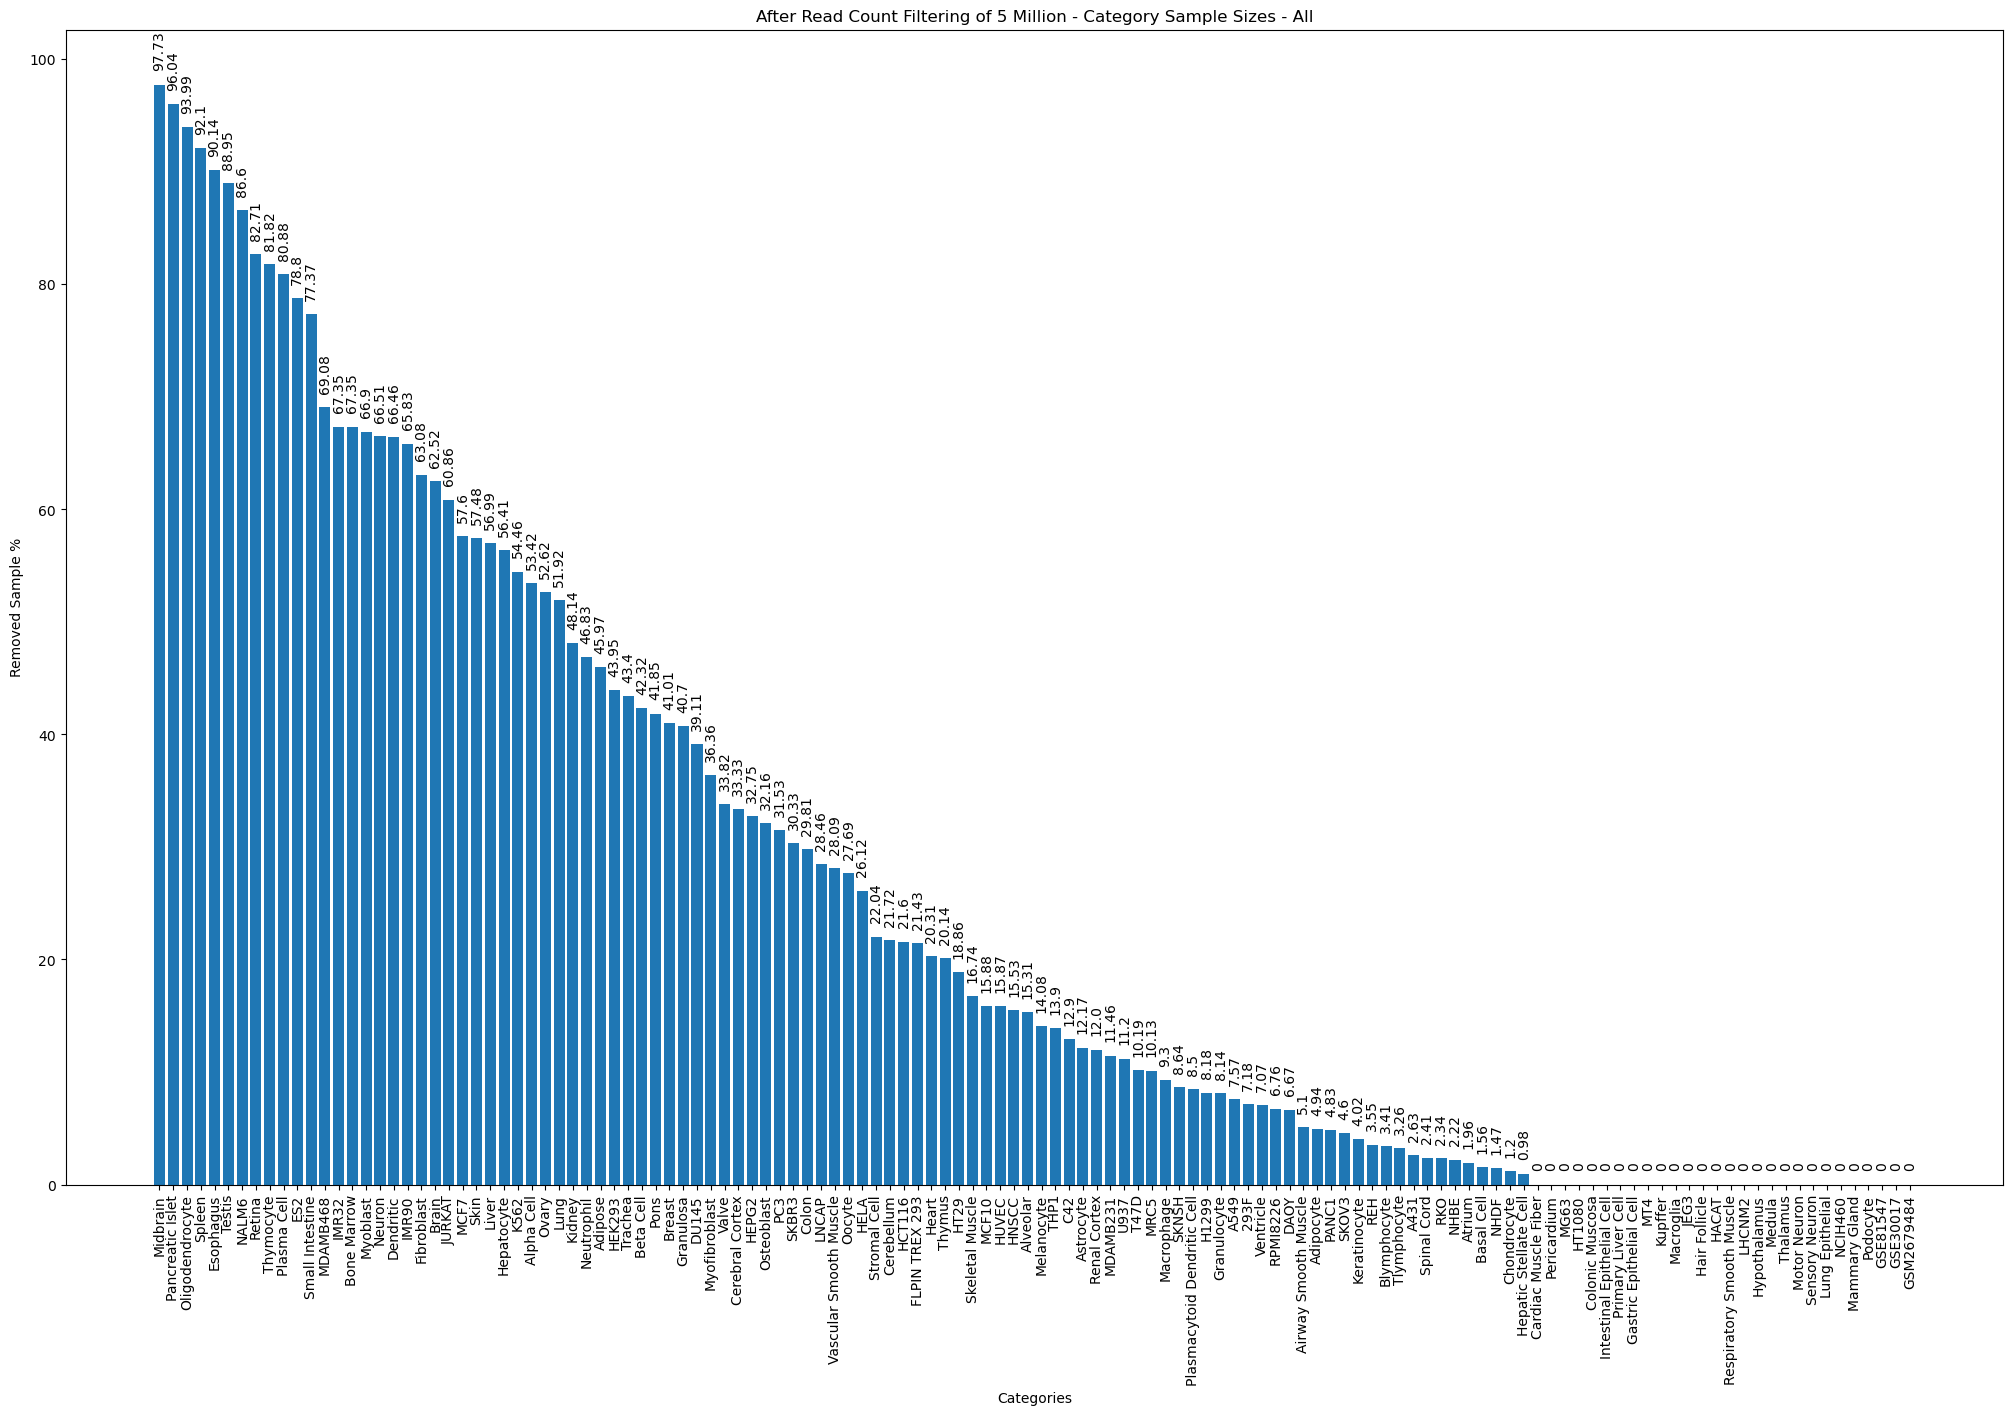

CPU times: user 2.06 s, sys: 395 ms, total: 2.45 s
Wall time: 2.35 s


In [3]:
%%time
import json
import matplotlib.pyplot as plt

# Load the data from the .json file
with open('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results/category_uniqueSampleSizes_dict_LW20230121.json', 'r') as f:
    org_biosamples_dict = json.load(f)

# Print the value of the key 'key1'
print(org_biosamples_dict['Heart'])

######
with open("filtered_category_uniqueSampleSizes_dict_LW20230123.json", "r") as f:
    filtered_sampleSize = json.load(f)

################################################################################################################
# Get the difference
import operator
sampleSize_diff = {}

for key in org_biosamples_dict:
    if key in filtered_sampleSize:
        remaining_samples = org_biosamples_dict[key] - filtered_sampleSize[key]
        if remaining_samples != 0:
            sampleSize_diff[key] = remaining_samples/org_biosamples_dict[key]
        else:
            sampleSize_diff[key] = 0

# sort the result dictionary in descending order based on the values
sorted_sampleSize_diff = dict(sorted(sampleSize_diff.items(), key=operator.itemgetter(1), reverse=True))

################################################################################################################
# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())
values = list(sorted_sampleSize_diff.values())

# convert to percentage
values = [v * 100 for v in values]

# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())
values = list(sorted_sampleSize_diff.values())

# convert to percentage
values = [v * 100 for v in values]

# Add the value labels
for i, v in enumerate(values):
    plt.annotate(str(round(v, 2)), xy=(i,v), xytext=(0,10), textcoords='offset points', ha='center', va='bottom', rotation = 90)

# create the bar plot
plt.bar(keys, values)
plt.xlabel('Categories')
plt.xticks(rotation=90)
fig = plt.gcf()
fig.set_size_inches(25, 15)
plt.ylabel('Removed Sample %')
plt.title('After Read Count Filtering of 5 Million - Category Sample Sizes - All')
plt.show()

709


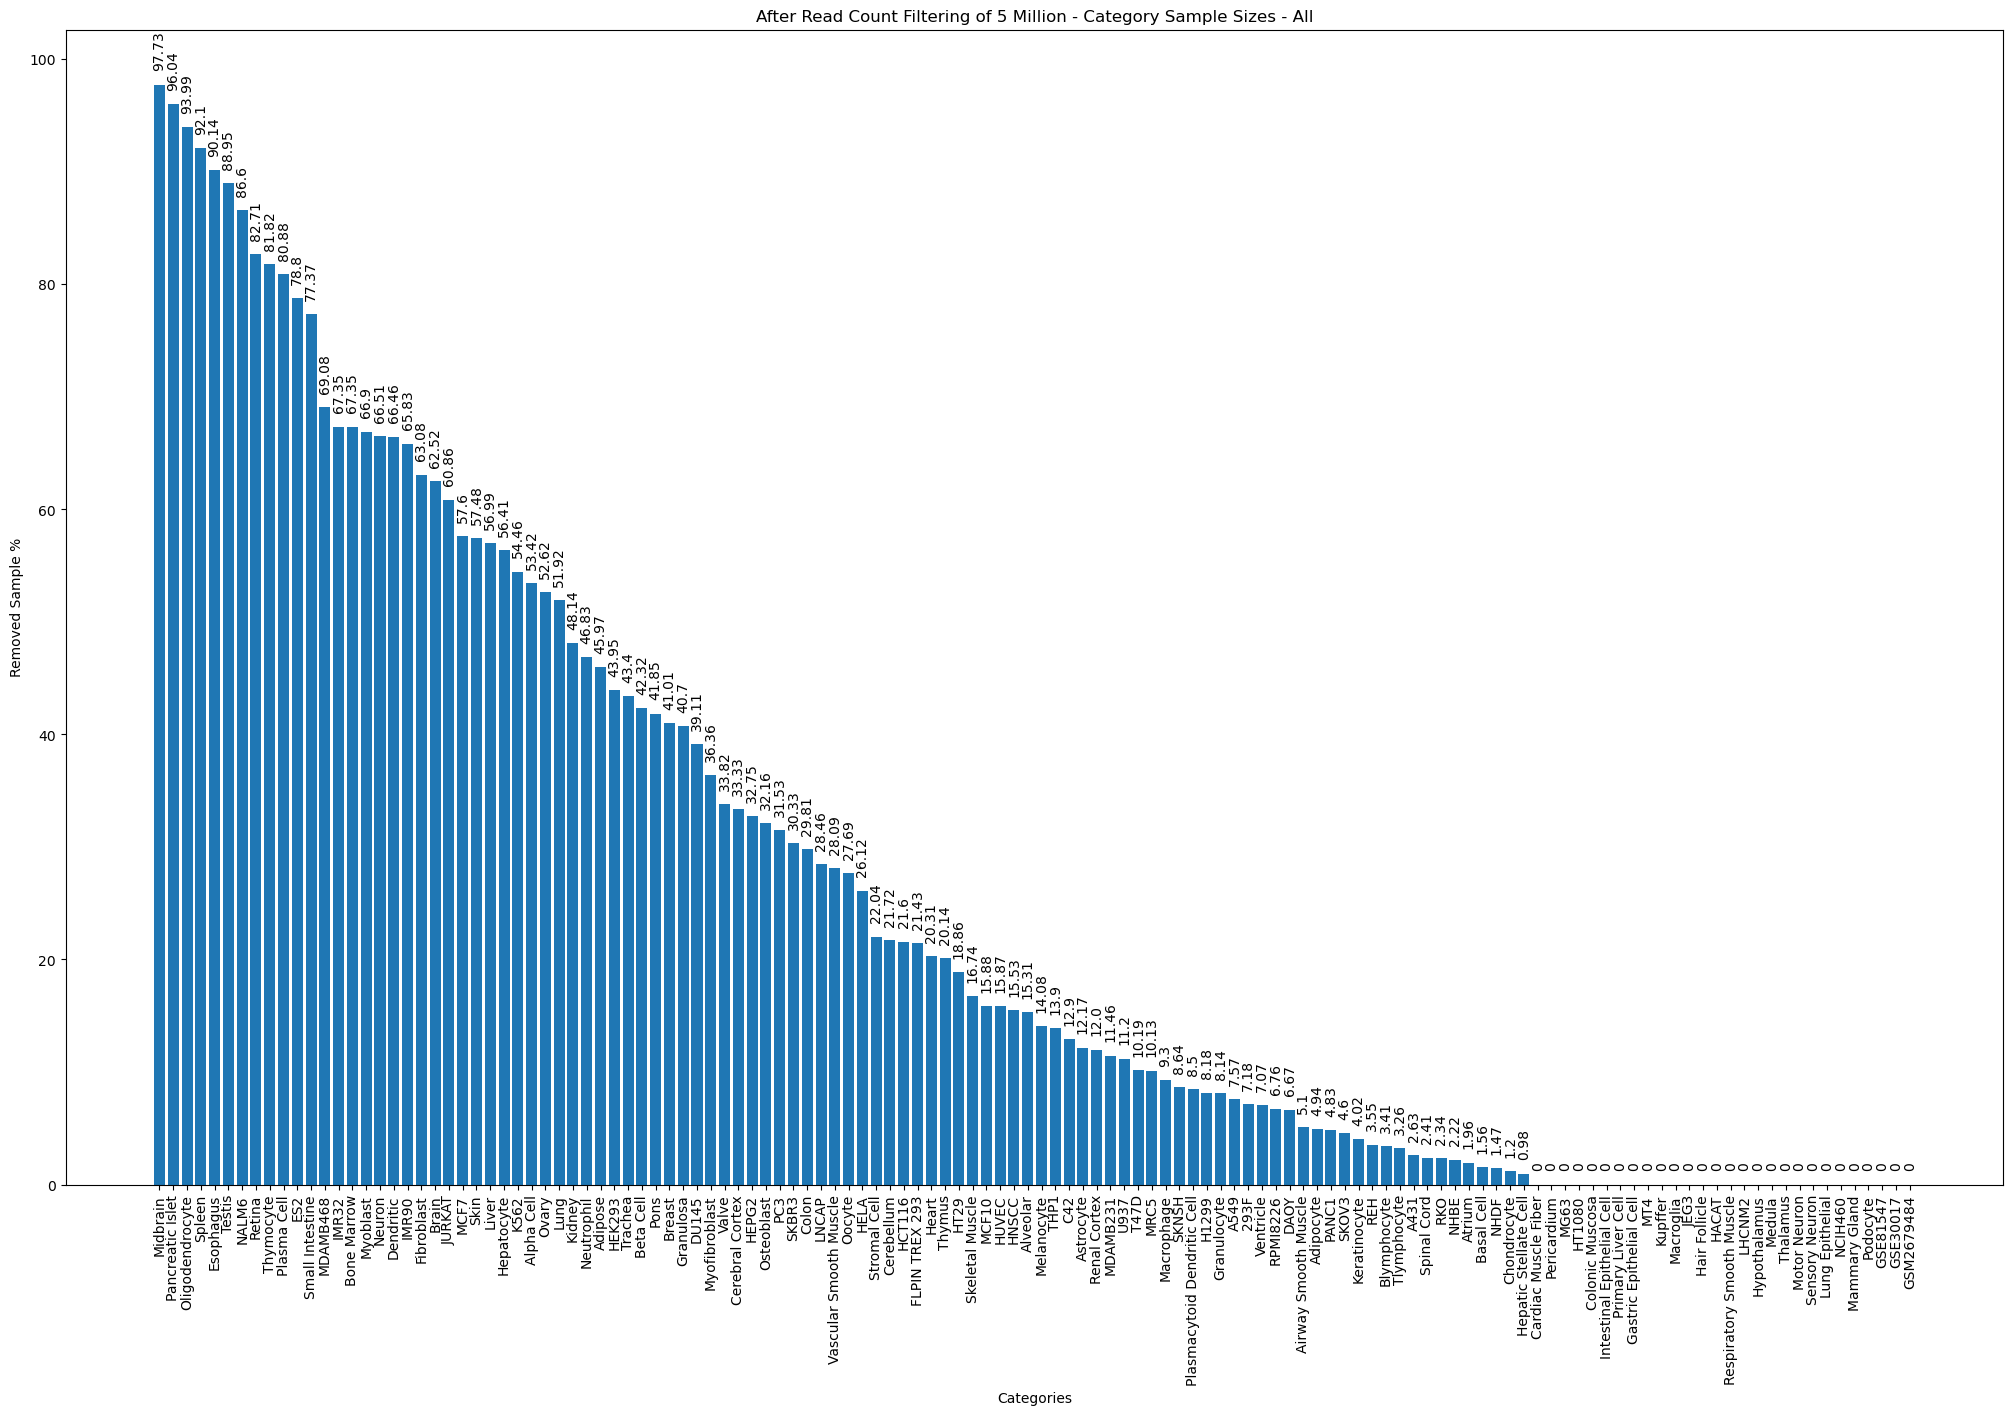

CPU times: user 2.37 s, sys: 498 ms, total: 2.87 s
Wall time: 3.63 s


In [1]:
%%time
import json
import matplotlib.pyplot as plt

# Load the data from the .json file
with open('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results/category_uniqueSampleSizes_dict_LW20230121.json', 'r') as f:
    org_biosamples_dict = json.load(f)

# Print the value of the key 'key1'
print(org_biosamples_dict['Heart'])

######
with open("filtered_category_uniqueSampleSizes_dict_LW20230123.json", "r") as f:
    filtered_sampleSize = json.load(f)

################################################################################################################
# Get the difference
import operator
sampleSize_diff = {}

for key in org_biosamples_dict:
    if key in filtered_sampleSize:
        remaining_samples = org_biosamples_dict[key] - filtered_sampleSize[key]
        if remaining_samples != 0:
            sampleSize_diff[key] = remaining_samples/org_biosamples_dict[key]
        else:
            sampleSize_diff[key] = 0

# sort the result dictionary in descending order based on the values
sorted_sampleSize_diff = dict(sorted(sampleSize_diff.items(), key=operator.itemgetter(1), reverse=True))

################################################################################################################
# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())
values = list(sorted_sampleSize_diff.values())

# convert to percentage
values = [v * 100 for v in values]

# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())
values = list(sorted_sampleSize_diff.values())

# convert to percentage
values = [v * 100 for v in values]

# Add the value labels
for i, v in enumerate(values):
    plt.annotate(str(round(v, 2)), xy=(i,v), xytext=(0,10), textcoords='offset points', ha='center', va='bottom', rotation = 90)

# create the bar plot
plt.bar(keys, values)
plt.xlabel('Categories')
plt.xticks(rotation=90)
fig = plt.gcf()
fig.set_size_inches(25, 15)
plt.ylabel('Removed Sample %')
plt.title('After Read Count Filtering of 5 Million - Category Sample Sizes - All')
plt.show()

In [32]:
sorted_sampleSize_diff

{'Stromal Cell': 1.0,
 'Bone Marrow': 1.0,
 'Intestinal Epithelial Cell': 1.0,
 'Small Intestine': 1.0,
 'Hepatic Stellate Cell': 1.0,
 'Alpha Cell': 1.0,
 'Beta Cell': 1.0,
 'Pancreatic Islet': 1.0,
 'Gastric Epithelial Cell': 1.0,
 'Blymphocyte': 1.0,
 'Plasma Cell': 1.0,
 'Plasmacytoid Dendritic Cell': 1.0,
 'Tlymphocyte': 1.0,
 'Basal Cell': 1.0,
 'Hair Follicle': 1.0,
 'Skeletal Muscle': 1.0,
 'Airway Smooth Muscle': 1.0,
 'Vascular Smooth Muscle': 1.0,
 'LHCNM2': 1.0,
 'Cerebral Cortex': 1.0,
 'SKNSH': 1.0,
 'NCIH460': 1.0,
 'Mammary Gland': 1.0,
 'Renal Cortex': 1.0,
 'FLPIN TREX 293': 1.0,
 'Spinal Cord': 0.9914089347079038,
 'MDAMB231': 0.9742120343839542,
 'Midbrain': 0.973062381852552,
 'MDAMB468': 0.963855421686747,
 'NALM6': 0.9217081850533808,
 'Spleen': 0.9201345102984447,
 'Oligodendrocyte': 0.9050632911392406,
 'Esophagus': 0.9013761467889908,
 'Testis': 0.8895104895104895,
 'ES2': 0.8290013679890561,
 'Retina': 0.8268916712030484,
 'Thymocyte': 0.8181818181818182,
 'C

In [42]:
selected_samples[27506]

'Human Kupffer cells'

In [59]:
len(category_sampleIdx_dict['HACAT'])

125

In [57]:
selected_samples_ = [selected_samples[i] for i in category_sampleIdx_dict['HACAT']]

In [58]:
selected_samples_

['HaCaT_VDR KO _VitaminD muinus',
 'HaCaT_VDR KO _VitaminD muinus',
 'HaCaT_VDR KO _VitaminD muinus',
 'HaCaT_VDR KO _VitaminD plus',
 'HaCaT_VDR KO _VitaminD plus',
 'HaCaT_VDR KO _VitaminD plus',
 'HaCat cell line',
 'HaCat cell line',
 'HaCat cell line',
 'HaCat cell line',
 'HaCat cell line',
 'HaCat cell line',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT cells',
 'HaCaT_siControl',
 'HaCaT_siControl',
 'HaCaT_siPTPN3',
 'HaCaT_siPTPN3',
 'HaCat cell line treated with terbinafine, re

In [60]:
category_sampleIdx_dict['HACAT']

[24390,
 24391,
 24392,
 24393,
 24394,
 24395,
 42604,
 42605,
 42606,
 42607,
 42608,
 42609,
 42610,
 42611,
 42612,
 42613,
 42614,
 42615,
 42616,
 42617,
 42618,
 42619,
 42620,
 42621,
 42622,
 42623,
 42624,
 42625,
 42626,
 42627,
 42628,
 42629,
 42630,
 42631,
 42632,
 42633,
 42634,
 42635,
 42636,
 42637,
 42638,
 42639,
 42640,
 42641,
 42642,
 42643,
 42644,
 42645,
 42646,
 42647,
 42648,
 42649,
 42650,
 42651,
 42652,
 42653,
 42654,
 42655,
 42656,
 42657,
 42658,
 42659,
 42660,
 42661,
 42662,
 42663,
 42664,
 42665,
 42666,
 42667,
 42668,
 42669,
 42670,
 42671,
 42672,
 42673,
 42674,
 42675,
 42676,
 42677,
 42678,
 42679,
 42680,
 42681,
 42682,
 42683,
 42684,
 42685,
 42686,
 42687,
 42688,
 42689,
 42690,
 42691,
 42692,
 42693,
 42694,
 42695,
 42696,
 42697,
 42698,
 42699,
 42700,
 42701,
 42702,
 42703,
 42704,
 42705,
 42706,
 42707,
 42708,
 42709,
 42710,
 42711,
 42712,
 42713,
 42714,
 42715,
 42716,
 42717,
 42718,
 42719,
 42720,
 42721,
 42722]

In [ ]:
list1 = [38711, 38712, 38713, 38714, 38715, 38716, 129570, 129571, 129572, 129573, 129574, 129575, 129576, 129577, 129578, 129579, 129580, 129581, 129582, 129583, 129584, 129585, 147033, 147034, 147035, 147036, 147037, 147038, 147039, 147040, 147041, 147042, 147043, 147044, 147045, 147046, 147047, 147048, 147049, 147050, 147051, 147052, 147053, 147054, 147055, 147056, 244273, 244274, 244275, 244276, 284078, 284079, 284080, 284081, 326231, 326232, 326233, 326234, 411322, 411323, 411324, 411325, 411326, 411327, 504030, 504031, 504032, 504033, 504034, 504035, 524649, 524650, 524651, 524652, 524653, 524654, 524655, 524656, 524657, 524658, 524659, 524660, 524661, 524662, 524663, 524664, 532443, 532444, 532445, 532446, 532447, 532448, 533267, 533268, 533269, 533270, 533271, 533272, 538185, 538186, 538187, 538188, 538189, 538190, 600025, 600026, 600027, 600028, 600029, 600030, 607530, 607531, 607532, 607533, 607534, 607535, 607536, 607537, 607538]

In [5]:
# Open ARCHS4 v2.1 Data
infile = "/home/ajoshi/archs4/data/archs4_gene_human_v2.1.h5"

# - Use read_direct method to improve read performance
with h5py.File(infile, 'r') as hdf5_file:

    meta = hdf5_file['meta']
    symbols = meta['genes']['gene_symbol'][:]
    source_name_ch1 = meta['samples']['source_name_ch1'][:]

# Decode source names using list comprehension
source_decoded = [x.decode('UTF-8') for x in source_name_ch1]

# Clean source names using regular expressions
source_cleaned = [re.sub(r'[-/\'\\ _]', '', x) for x in source_decoded]

In [71]:
import h5py

gene_length_list = []

# Open the CSV file
with open('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/data_results/edited_gene_name_length_idx_data.csv', 'r') as f:
    # Skip the header row
    next(f)

     # Read the remaining rows
    reader = csv.reader(f)
    for row in reader:
        gene_length_list.append(row[3])

print(gene_length_list[0:3])

['3374', '2409', '9208']


In [10]:
removed_samples = [source_name_ch1[x] for x in not_in_list1]

print(set(removed_samples))

{b'Biochain:R-1234122-P', b'Sample_4_180', b'CNE1-MOCK_RNA-seq', b'microRNA from sample B constructed by the kit from Bioo scientific', b'human normal pancreas tissue (Zyagen)', b'Sample_5_180', b'Sample_5_0', b'CNE1-BART7_RNA-seq', b'in vitro cultured primary coronary artery smooth muscle cells', b'Biochain:R-1234142-P', b'Ctrl_RBM10.OE.1_RNA-Seq', b'EB', b'LCL cell line established using EBV B95-8 BACmid', b'Sample_7_7', b'Biochain:R-1234171-P', b'mammary tumor xenograft', b'Sample_3_180', b'KYSE70_shSOX2_Day 0', b'KYSE70_shTP63_Day 4', b'Sample_3_7', b'KYSE70_shTP63_Day 0', b'Dorsolateral prefrontal cortex', b'RBM10.OE.1_RNA-Seq', b'MDA-MB-453 cells transfected with control siRNA followed by vehicle treatment', b'Tonsillar Na\xc3\x83\xc2\xafve B cells', b'GM12878', b'gastric adenocarcinoma cells', b'WSUDLCL2 cell line', b'microRNA from sample C constructed by the kit from Bioo scientific', b'Biochain:R-1234201-P', b'Sample_6_7', b'Prefrontal Cortex', b'Sample_7_0', b'CD4+ T cells', 

In [11]:
source_decoded = [x.decode('UTF-8') for x in source_name_ch1]

{b'293S cells',
 b'293T cell line',
 b'786-O-RNA-seq',
 b'BJAB cells_empty_RISC-IP',
 b'Biochain:R-1234010-P',
 b'Biochain:R-1234035-P',
 b'Biochain:R-1234086-P',
 b'Biochain:R-1234090-P',
 b'Biochain:R-1234122-P',
 b'Biochain:R-1234142-P',
 b'Biochain:R-1234149-P',
 b'Biochain:R-1234152-P',
 b'Biochain:R-1234171-P',
 b'Biochain:R-1234183-P',
 b'Biochain:R-1234201-P',
 b'Biochain:R-1234218-P',
 b'Blood',
 b'Bronchial Epithelial Cells',
 b'CD34+ cells',
 b'CD4+ T cells',
 b'CNE1-BART1_RNA-seq',
 b'CNE1-BART3_RNA-seq',
 b'CNE1-BART7_RNA-seq',
 b'CNE1-MOCK_RNA-seq',
 b'Ctrl_RBM10.KD.24h_RNA-Seq',
 b'Ctrl_RBM10.OE.1_RNA-Seq',
 b'Dorsolateral prefrontal cortex',
 b'EB',
 b'Farage cell line',
 b'Fertile mature sperm',
 b'GM12878',
 b'Gastric carcinoma cell line',
 b'HDMYZ, 0ug/ml Actinomycin D, 0 hour',
 b'HDMYZ, 2ug/ml Actinomycin D, 12 hours',
 b'HDMYZ, 2ug/ml Actinomycin D, 4 hours',
 b'HEL cells',
 b'Human DLBCL cel line',
 b'Human Fib X Human Fib Homokaryons',
 b'Human microvascular end

In [12]:
len({b'Biochain:R-1234122-P', b'Sample_4_180', b'CNE1-MOCK_RNA-seq', b'microRNA from sample B constructed by the kit from Bioo scientific', b'human normal pancreas tissue (Zyagen)', b'Sample_5_180', b'Sample_5_0', b'CNE1-BART7_RNA-seq', b'in vitro cultured primary coronary artery smooth muscle cells', b'Biochain:R-1234142-P', b'Ctrl_RBM10.OE.1_RNA-Seq', b'EB', b'LCL cell line established using EBV B95-8 BACmid', b'Sample_7_7', b'Biochain:R-1234171-P', b'mammary tumor xenograft', b'Sample_3_180', b'KYSE70_shSOX2_Day 0', b'KYSE70_shTP63_Day 4', b'Sample_3_7', b'KYSE70_shTP63_Day 0', b'Dorsolateral prefrontal cortex', b'RBM10.OE.1_RNA-Seq', b'MDA-MB-453 cells transfected with control siRNA followed by vehicle treatment', b'Tonsillar Na\xc3\x83\xc2\xafve B cells', b'GM12878', b'gastric adenocarcinoma cells', b'WSUDLCL2 cell line', b'microRNA from sample C constructed by the kit from Bioo scientific', b'Biochain:R-1234201-P', b'Sample_6_7', b'Prefrontal Cortex', b'Sample_7_0', b'CD4+ T cells', b'Human Fib X Human Fib Homokaryons', b'LCL cell line established using EBV B95-8 BACmid lacking ebv-mir-BHRF1-2 (D2)', b'corneal endothelial cells', b'microRNA from sample A constructed by the kit from Bioo scientific', b'293S cells', b'Biochain:R-1234035-P', b'MDA-MB-453 cells transfected with control siRNA followed by DHT treatment', b'iPSC', b'MDA-MB-453 cells transfected with MYC siRNA followed by DHT treatment', b'Kasumi-1 cells', b'Biochain:R-1234183-P', b'KYSE70_shSOX2_Day 4', b'OCI-Ly1 cell line', b'definitive endoderm cells', b'iPS', b'LCL cell line established using EBV B95-8 BACmid lacking ebv-mir-BHRF1-1 (D1), RNA-seq biological replicate #2', b'cord blood', b'KBM7', b'Normal.2_RNA-Seq', b'HDMYZ, 2ug/ml Actinomycin D, 12 hours', b'undifferentiated human ESCs', b'BJAB cells_empty_RISC-IP', b'NPC', b'human PSCs', b'Sample_8_7', b'NTera2/D1 cells', b'LCL cell line established using EBV B95-8 BACmid lacking ebv-mir-BHRF1-1 (D1), RNA-seq biological replicate #1', b'ME-1 (leukemic)', b'Sample_1_180', b'microRNA from sample C constructed by the kit from NEB', b'RBM10.KD.48h.1_RNA-Seq', b'293T cell line', b'Patient_RNA-Seq', b'immortalized T-cell line', b'LSEC', b'CNE1-BART1_RNA-seq', b'HEL cells', b'Blood', b'Sample_5_7', b'Induced endothelial cell', b'Human DLBCL cel line', b'Sample_8_180', b'Human microvascular endothilial cell', b'Sample_2_7', b'placenta', b'Biochain:R-1234149-P', b'Primary Human Umbilical Vein Endothelial Cells', b'microRNA from sample A constructed by the kit from Illumina', b'OCI-Ly7 cell line', b'Sample_2_0', b'Sample_4_0', b'Biochain:R-1234086-P', b'Sample_6_0', b'cells in culture', b'Biochain:R-1234090-P', b'HDMYZ, 2ug/ml Actinomycin D, 4 hours', b'Universal Human Reference RNA (UHRR) from Stratagene', b'embryonic stem cells', b'CD34+ cells', b'in vitro derived hepatoblast', b'induced pluripotent stem cells', b'Sample_4_7', b'NB1 cell line', b'Sample_9_180', b'Biochain:R-1234218-P', b'MiaPaCa-2', b'Biochain:R-1234152-P', b'Sample_9_7', b'SUDHL5 cell line', b'Biochain:R-1234010-P', b'Sample_1_7', b'Bronchial Epithelial Cells', b'pancreatic progenitors cells', b'CNE1-BART3_RNA-seq', b'microRNA from sample A constructed by the kit from NEB', b'Sample_3_0', b'Fertile mature sperm', b'Milk Fat Layer', b'Gastric carcinoma cell line', b'whole blood', b'Pfeiffer cell line', b'Ctrl_RBM10.KD.24h_RNA-Seq', b'Tonsillar Germinal Center B cells', b'Sample_9_0', b'786-O-RNA-seq', b'eCenH3 RNA-seq', b'HDMYZ, 0ug/ml Actinomycin D, 0 hour', b'Sample_6_180', b'OS-RC-2-RNA-seq', b'Sample_8_0', b'Lymph Node', b'LCL cell line established using EBV B95-8 BACmid lacking ebv-mir-BHRF1-3 (D3)', b'Farage cell line', b'RBM10.KD.72h_RNA-Seq', b'Sample_1_0', b'microRNA from sample B constructed by the kit from NEB'})


130

In [13]:
source_decoded = [x.decode('UTF-8') for x in {b'Biochain:R-1234122-P', b'Sample_4_180', b'CNE1-MOCK_RNA-seq', b'microRNA from sample B constructed by the kit from Bioo scientific', b'human normal pancreas tissue (Zyagen)', b'Sample_5_180', b'Sample_5_0', b'CNE1-BART7_RNA-seq', b'in vitro cultured primary coronary artery smooth muscle cells', b'Biochain:R-1234142-P', b'Ctrl_RBM10.OE.1_RNA-Seq', b'EB', b'LCL cell line established using EBV B95-8 BACmid', b'Sample_7_7', b'Biochain:R-1234171-P', b'mammary tumor xenograft', b'Sample_3_180', b'KYSE70_shSOX2_Day 0', b'KYSE70_shTP63_Day 4', b'Sample_3_7', b'KYSE70_shTP63_Day 0', b'Dorsolateral prefrontal cortex', b'RBM10.OE.1_RNA-Seq', b'MDA-MB-453 cells transfected with control siRNA followed by vehicle treatment', b'Tonsillar Na\xc3\x83\xc2\xafve B cells', b'GM12878', b'gastric adenocarcinoma cells', b'WSUDLCL2 cell line', b'microRNA from sample C constructed by the kit from Bioo scientific', b'Biochain:R-1234201-P', b'Sample_6_7', b'Prefrontal Cortex', b'Sample_7_0', b'CD4+ T cells', b'Human Fib X Human Fib Homokaryons', b'LCL cell line established using EBV B95-8 BACmid lacking ebv-mir-BHRF1-2 (D2)', b'corneal endothelial cells', b'microRNA from sample A constructed by the kit from Bioo scientific', b'293S cells', b'Biochain:R-1234035-P', b'MDA-MB-453 cells transfected with control siRNA followed by DHT treatment', b'iPSC', b'MDA-MB-453 cells transfected with MYC siRNA followed by DHT treatment', b'Kasumi-1 cells', b'Biochain:R-1234183-P', b'KYSE70_shSOX2_Day 4', b'OCI-Ly1 cell line', b'definitive endoderm cells', b'iPS', b'LCL cell line established using EBV B95-8 BACmid lacking ebv-mir-BHRF1-1 (D1), RNA-seq biological replicate #2', b'cord blood', b'KBM7', b'Normal.2_RNA-Seq', b'HDMYZ, 2ug/ml Actinomycin D, 12 hours', b'undifferentiated human ESCs', b'BJAB cells_empty_RISC-IP', b'NPC', b'human PSCs', b'Sample_8_7', b'NTera2/D1 cells', b'LCL cell line established using EBV B95-8 BACmid lacking ebv-mir-BHRF1-1 (D1), RNA-seq biological replicate #1', b'ME-1 (leukemic)', b'Sample_1_180', b'microRNA from sample C constructed by the kit from NEB', b'RBM10.KD.48h.1_RNA-Seq', b'293T cell line', b'Patient_RNA-Seq', b'immortalized T-cell line', b'LSEC', b'CNE1-BART1_RNA-seq', b'HEL cells', b'Blood', b'Sample_5_7', b'Induced endothelial cell', b'Human DLBCL cel line', b'Sample_8_180', b'Human microvascular endothilial cell', b'Sample_2_7', b'placenta', b'Biochain:R-1234149-P', b'Primary Human Umbilical Vein Endothelial Cells', b'microRNA from sample A constructed by the kit from Illumina', b'OCI-Ly7 cell line', b'Sample_2_0', b'Sample_4_0', b'Biochain:R-1234086-P', b'Sample_6_0', b'cells in culture', b'Biochain:R-1234090-P', b'HDMYZ, 2ug/ml Actinomycin D, 4 hours', b'Universal Human Reference RNA (UHRR) from Stratagene', b'embryonic stem cells', b'CD34+ cells', b'in vitro derived hepatoblast', b'induced pluripotent stem cells', b'Sample_4_7', b'NB1 cell line', b'Sample_9_180', b'Biochain:R-1234218-P', b'MiaPaCa-2', b'Biochain:R-1234152-P', b'Sample_9_7', b'SUDHL5 cell line', b'Biochain:R-1234010-P', b'Sample_1_7', b'Bronchial Epithelial Cells', b'pancreatic progenitors cells', b'CNE1-BART3_RNA-seq', b'microRNA from sample A constructed by the kit from NEB', b'Sample_3_0', b'Fertile mature sperm', b'Milk Fat Layer', b'Gastric carcinoma cell line', b'whole blood', b'Pfeiffer cell line', b'Ctrl_RBM10.KD.24h_RNA-Seq', b'Tonsillar Germinal Center B cells', b'Sample_9_0', b'786-O-RNA-seq', b'eCenH3 RNA-seq', b'HDMYZ, 0ug/ml Actinomycin D, 0 hour', b'Sample_6_180', b'OS-RC-2-RNA-seq', b'Sample_8_0', b'Lymph Node', b'LCL cell line established using EBV B95-8 BACmid lacking ebv-mir-BHRF1-3 (D3)', b'Farage cell line', b'RBM10.KD.72h_RNA-Seq', b'Sample_1_0', b'microRNA from sample B constructed by the kit from NEB'}]

In [14]:
source_decoded

['Biochain:R-1234122-P',
 'Sample_4_180',
 'CNE1-MOCK_RNA-seq',
 'microRNA from sample B constructed by the kit from Bioo scientific',
 'human normal pancreas tissue (Zyagen)',
 'Sample_5_180',
 'Sample_5_0',
 'CNE1-BART7_RNA-seq',
 'in vitro cultured primary coronary artery smooth muscle cells',
 'Biochain:R-1234142-P',
 'Ctrl_RBM10.OE.1_RNA-Seq',
 'EB',
 'LCL cell line established using EBV B95-8 BACmid',
 'Sample_7_7',
 'Biochain:R-1234171-P',
 'mammary tumor xenograft',
 'Sample_3_180',
 'KYSE70_shSOX2_Day 0',
 'KYSE70_shTP63_Day 4',
 'Sample_3_7',
 'KYSE70_shTP63_Day 0',
 'Dorsolateral prefrontal cortex',
 'RBM10.OE.1_RNA-Seq',
 'MDA-MB-453 cells transfected with control siRNA followed by vehicle treatment',
 'Tonsillar NaÃ¯ve B cells',
 'GM12878',
 'gastric adenocarcinoma cells',
 'WSUDLCL2 cell line',
 'microRNA from sample C constructed by the kit from Bioo scientific',
 'Biochain:R-1234201-P',
 'Sample_6_7',
 'Prefrontal Cortex',
 'Sample_7_0',
 'CD4+ T cells',
 'Human Fib X H

In [15]:
len(['Biochain:R-1234122-P',
 'Sample_4_180',
 'CNE1-MOCK_RNA-seq',
 'microRNA from sample B constructed by the kit from Bioo scientific',
 'human normal pancreas tissue (Zyagen)',
 'Sample_5_180',
 'Sample_5_0',
 'CNE1-BART7_RNA-seq',
 'in vitro cultured primary coronary artery smooth muscle cells',
 'Biochain:R-1234142-P',
 'Ctrl_RBM10.OE.1_RNA-Seq',
 'EB',
 'LCL cell line established using EBV B95-8 BACmid',
 'Sample_7_7',
 'Biochain:R-1234171-P',
 'mammary tumor xenograft',
 'Sample_3_180',
 'KYSE70_shSOX2_Day 0',
 'KYSE70_shTP63_Day 4',
 'Sample_3_7'])

20